# Why BEDC misses its loss target: Python analysis

**Question:** BEDC collects better than any other Nigerian distribution company, yet its ATC&C loss is far above the regulator's target. Is the leak in **billing** or in **collection**, and how big is it in naira?

**Data:** `disco_quarterly.csv`, built from the NERC Q1 2026 and Q2 2026 quarterly reports (11 distribution companies x 3 quarters). BEDC appears as `Benin`.

**How to run:** put this notebook in the same folder as `disco_quarterly.csv` and run all cells. Requires `pandas`, `numpy`, `matplotlib`. Charts are saved to `charts/`.

**Rule followed throughout:** state the question, run it, say what the output tells us, and say what it does *not* tell us.

In [1]:
import pandas as pd, numpy as np, os
import matplotlib.pyplot as plt, matplotlib
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
pd.set_option("display.width", 160)
os.makedirs("charts", exist_ok=True)

ME = "Benin"          # BEDC's name in NERC tables
TARGET = 0.1723       # BEDC's 2026 MYTO ATC&C target (NERC)

df = pd.read_csv("disco_quarterly.csv")
df.head()

,disco,quarter,gwh_received,gwh_billed,naira_received_bn,naira_billed_bn,naira_collected_bn,atcc_reported_pct,myto_2026_target_pct,active_customers,metered_customers
0,Abuja,Q4-2025,"1,273.470",972.000,157.090,130.440,108.410,30.990,NaN,NaN,NaN
1,Benin,Q4-2025,779.520,683.170,95.690,62.690,53.110,44.500,NaN,NaN,NaN
2,Eko,Q4-2025,"1,061.560",942.000,130.890,124.320,112.300,14.200,NaN,NaN,NaN
3,Enugu,Q4-2025,695.650,511.000,84.310,67.410,51.750,38.620,NaN,NaN,NaN
4,Ibadan,Q4-2025,956.580,849.050,117.030,84.340,67.280,42.510,NaN,NaN,NaN


## 1. Inspect the data before changing anything
**Grain:** one row per distribution company per quarter. Money columns are in naira billion, energy in GWh.

In [2]:
print("Rows, columns:", df.shape)
print("\nRows per quarter:\n", df.groupby("quarter").size().to_string())
print("\nMissing values per column:\n", df.isna().sum()[df.isna().sum() > 0].to_string())
print("\nDuplicate (disco, quarter) pairs:", df.duplicated(["disco", "quarter"]).sum())
print("\nValue ranges:")
df.describe().loc[["min", "max"]].T

Rows, columns: (33, 11)

Rows per quarter:
 quarter
Q1-2026    11
Q2-2026    11
Q4-2025    11

Missing values per column:
 myto_2026_target_pct    11
active_customers        11
metered_customers       11

Duplicate (disco, quarter) pairs: 0

Value ranges:


,min,max
gwh_received,154.410,"1,273.470"
gwh_billed,126.640,"1,014.710"
naira_received_bn,21.060,160.630
naira_billed_bn,13.230,135.180
naira_collected_bn,9.690,117.560
atcc_reported_pct,14.200,69.660
myto_2026_target_pct,13.540,29.000
active_customers,"511,580.000","2,536,676.000"
metered_customers,"169,619.000","1,461,585.000"


**What this tells us:** 33 rows, no duplicates. Missing values are expected, not errors: the 2026 loss target and customer counts do not exist for Q4 2025 in the source tables, so those cells are blank and are never filled in.

**What it does not tell us:** whether the typed numbers match the PDFs. The next step tests that indirectly.

## 2. Validate the data: recompute ATC&C and compare with NERC's reported figure
ATC&C = 1 - billing efficiency x collection efficiency. If any figure was mistyped, the recomputed value would drift from the published ATC&C.

In [3]:
d = df.copy()
d["eae"]  = d.gwh_billed / d.gwh_received                   # energy accounting efficiency (GWh basis)
d["be"]   = d.naira_billed_bn / d.naira_received_bn          # billing efficiency (naira basis)
d["ce"]   = d.naira_collected_bn / d.naira_billed_bn         # collection efficiency
d["atcc"] = 1 - d.be * d.ce                                  # ATC&C loss, calculated
d["check_pp"] = (d.atcc * 100 - d.atcc_reported_pct).abs()   # gap vs NERC, percentage points

print(d.groupby("quarter").check_pp.max().round(4).to_string())
assert d.check_pp.max() < 0.02, "A typed value may be wrong"
print("\nAll 33 rows reconcile with NERC's reported ATC&C within 0.02pp.")

quarter
Q1-2026   0.011
Q2-2026   0.008
Q4-2025   0.016

All 33 rows reconcile with NERC's reported ATC&C within 0.02pp.


**What this tells us:** the transcription is internally consistent across all 33 rows.

**What it does not tell us:** it cannot catch an error that moves billed and received naira together. A spot-check against the PDFs is still needed before publishing.

## 3. Derived measures (defined by this analysis, not published by NERC)
- **Tariff realization** = billing efficiency / energy accounting efficiency. How much of the average allowed tariff each billed unit of energy earns.
- **Volumetric billing loss** = unbilled energy (GWh) x average allowed tariff. Energy that never reached a bill.
- **Tariff-mix billing loss** = total billing loss - volumetric loss. Energy that *was* billed, but at below-average value.

In [4]:
d["tariff_realization"] = d.be / d.eae
d["avg_tariff_per_kwh"] = d.naira_received_bn / d.gwh_received * 1000   # naira per kWh
d["billing_loss_bn"]    = d.naira_received_bn - d.naira_billed_bn
d["volumetric_bn"]      = (d.gwh_received - d.gwh_billed) * d.naira_received_bn / d.gwh_received
d["tariff_mix_bn"]      = d.billing_loss_bn - d.volumetric_bn
d["metering_rate"]      = d.metered_customers / d.active_customers

b = d[d.disco == ME].set_index("quarter").loc[["Q4-2025", "Q1-2026", "Q2-2026"]]
view = b[["eae", "be", "ce", "atcc", "tariff_realization", "billing_loss_bn", "volumetric_bn", "tariff_mix_bn", "metering_rate"]].T
view.columns.name = None
view

,Q4-2025,Q1-2026,Q2-2026
eae,0.876,0.872,0.865
be,0.655,0.708,0.714
ce,0.847,0.852,0.927
atcc,0.445,0.397,0.338
tariff_realization,0.748,0.812,0.825
billing_loss_bn,33.000,23.580,22.180
volumetric_bn,11.827,10.310,10.425
tariff_mix_bn,21.173,13.270,11.755
metering_rate,NaN,0.580,0.610


**What this tells us (BEDC, Q2 2026):** collection efficiency is about 92.7%, but billing efficiency is only 71.4%. By volume BEDC bills 86.5% of its energy, yet by value only 71.4%, so billed energy earns about 82.5% of the average tariff.

**What it does not tell us:** *why* billed energy is worth less. Possible reasons (lower-tariff bands, capped estimated bills for unmetered customers) are hypotheses that need BEDC's feeder-level data.

**Caution:** NERC adjusted the tariff for VAT from Q1 2026, so Q4 2025 is not fully comparable with 2026 quarters.

## 4. How does BEDC compare with the other 10 companies? (Q2 2026)

In [5]:
p = d[d.quarter == "Q2-2026"].copy()
p["gap_to_target_pp"] = (p.atcc - p.myto_2026_target_pct / 100) * 100
p["be_minus_eae_pp"]  = (p.be - p.eae) * 100
for col, asc in [("be", False), ("ce", False), ("tariff_realization", False), ("atcc", True), ("metering_rate", False)]:
    p["rank_" + col] = p[col].rank(ascending=asc, method="min").astype(int)

cols = ["disco", "be", "ce", "atcc", "myto_2026_target_pct", "gap_to_target_pp", "be_minus_eae_pp",
        "rank_be", "rank_ce", "rank_atcc", "rank_tariff_realization", "rank_metering_rate"]
p.sort_values("atcc")[cols].reset_index(drop=True)

,disco,be,ce,atcc,myto_2026_target_pct,gap_to_target_pp,be_minus_eae_pp,rank_be,rank_ce,rank_atcc,rank_tariff_realization,rank_metering_rate
0,Eko,0.884,0.894,0.210,14.190,6.812,4.827,1,3,1,1,1
1,Ikeja,0.812,0.922,0.251,13.540,11.584,-6.291,3,2,2,7,2
2,Port Harcourt,0.807,0.873,0.296,16.670,12.923,-3.966,5,4,3,6,4
3,Abuja,0.811,0.835,0.323,16.970,15.340,-0.116,4,5,4,4,3
4,Benin,0.714,0.927,0.338,17.230,16.607,-15.170,8,1,5,9,5
5,Enugu,0.795,0.795,0.368,18.080,18.713,3.885,6,7,6,2,7
6,Ibadan,0.747,0.803,0.400,17.500,22.531,-14.409,7,6,7,8,6
7,Yola,0.665,0.691,0.540,29.000,25.032,-15.507,10,8,8,10,10
8,Kano,0.829,0.477,0.604,17.450,42.981,3.212,2,11,9,3,8
9,Jos,0.703,0.550,0.613,20.800,40.494,-3.450,9,9,10,5,11


**What this tells us:** BEDC ranks 1st of 11 on collection but 8th on billing, 5th on ATC&C loss, and 9th on tariff realization. Its BE-EAE gap (-15.2pp) is the third widest. NERC itself reads a large negative gap as energy skewed toward less commercially viable feeders.

**What it does not tell us:** that BEDC is "worse managed" than peers. Companies differ in customer mix, geography, and supply, so the ranks are a starting point for questions, not a verdict.

## 5. What drove the Q1 to Q2 improvement? (ATC&C bridge)
ATC&C = 1 - BE x CE. The change is split exactly into a **collection effect** (billing held at Q1) and a **billing effect** (collection at Q2).

In [6]:
q1, q2 = b.loc["Q1-2026"], b.loc["Q2-2026"]
total    = (q1.atcc - q2.atcc) * 100
coll_eff = q1.be * (q2.ce - q1.ce) * 100
bill_eff = (q2.be - q1.be) * q2.ce * 100
assert abs(coll_eff + bill_eff - total) < 1e-9

print(f"ATC&C: {q1.atcc:.1%} -> {q2.atcc:.1%}  (improvement {total:.2f}pp)")
print(f"  collection effect: {coll_eff:.2f}pp  ({coll_eff/total:.0%} of improvement)")
print(f"  billing effect:    {bill_eff:.2f}pp  ({bill_eff/total:.0%} of improvement)")

ATC&C: 39.7% -> 33.8%  (improvement 5.87pp)
  collection effect: 5.32pp  (91% of improvement)
  billing effect:    0.55pp  (9% of improvement)


**What this tells us:** about 91% of the improvement came from collection and only 9% from billing. Q1 to Q2 uses the same NERC method, so this comparison is like-for-like.

**What it does not tell us:** whether the collection jump is durable. Billed naira fell 3.2% and energy taken fell while collections rose, so part of the jump may be timing or arrears recovery. Monthly data is needed to test that.

## 6. Gap to target: how much must billing improve?

In [7]:
gap_pp         = (q2.atcc - TARGET) * 100
need_be_now_ce = (1 - TARGET) / q2.ce        # billing efficiency needed at today's collection
need_be_perfect = 1 - TARGET                  # billing efficiency needed with 100% collection
atcc_if_perfect = 1 - q2.be                   # ATC&C if collection were 100%
rev_at_target   = q2.naira_received_bn * (1 - TARGET)
shortfall       = rev_at_target - q2.naira_collected_bn
shortfall_q1    = q1.naira_received_bn * (1 - TARGET) - q1.naira_collected_bn

print(f"ATC&C gap to target:                       {gap_pp:.1f}pp")
print(f"ATC&C if collection were a perfect 100%:   {atcc_if_perfect:.1%}  (target {TARGET:.1%})")
print(f"Billing efficiency needed (today's CE):    {need_be_now_ce:.1%}   (now {q2.be:.1%})")
print(f"Billing efficiency needed (100% CE):       {need_be_perfect:.1%}")
print(f"Revenue at target losses (Q2):             N{rev_at_target:.1f}bn vs collected N{q2.naira_collected_bn:.1f}bn")
print(f"Shortfall vs target (Q2 / Q1):             N{shortfall:.1f}bn / N{shortfall_q1:.1f}bn per quarter")

ATC&C gap to target:                       16.6pp
ATC&C if collection were a perfect 100%:   28.6%  (target 17.2%)
Billing efficiency needed (today's CE):    89.3%   (now 71.4%)
Billing efficiency needed (100% CE):       82.8%
Revenue at target losses (Q2):             N64.1bn vs collected N51.3bn
Shortfall vs target (Q2 / Q1):             N12.9bn / N18.1bn per quarter


**What this tells us:** collection is close to its ceiling. Even perfect collection leaves ATC&C at about 28.6%, so billing is the binding constraint. The Q2 shortfall against target losses is about N12.9bn.

**What it does not tell us:** how much of the gap is realistically recoverable. A target loss of 17.2% is a regulatory assumption, not a guarantee.

## 7. What is fixing billing worth? (scenario analysis)
Assumes extra bills are collected at today's collection rate. An illustration, not a forecast.

In [8]:
rows = []
for share in (0.25, 0.50, 1.00):
    extra_bill = share * q2.tariff_mix_bn
    extra_cash = extra_bill * q2.ce
    new_be     = (q2.naira_billed_bn + extra_bill) / q2.naira_received_bn
    rows.append({"share of tariff-mix loss recovered": f"{share:.0%}", "extra billing (Nbn/qtr)": extra_bill,
                 "extra cash (Nbn/qtr)": extra_cash, "new billing eff.": new_be, "new ATC&C": 1 - new_be * q2.ce,
                 "extra cash (Nbn/yr, x4)": extra_cash * 4})
pd.DataFrame(rows)

,share of tariff-mix loss recovered,extra billing (Nbn/qtr),extra cash (Nbn/qtr),new billing eff.,new ATC&C,"extra cash (Nbn/yr, x4)"
0,25%,2.939,2.724,0.752,0.303,10.896
1,50%,5.878,5.448,0.790,0.268,21.793
2,100%,11.755,10.896,0.865,0.198,43.586


**What this tells us:** recovering a quarter of the tariff-mix loss is worth about N2.7bn of cash per quarter. Even full recovery leaves ATC&C near 19.8%, above the 17.2% target, so unbilled energy must also fall.

**What it does not tell us:** that the tariff-mix loss is recoverable at all. If it comes from legitimate lower tariff bands, part of it cannot be billed higher.

## 8. Visualisations
Four charts, saved to `charts/`. Colours: green = cash collected, red = never billed, violet = billed below average tariff.

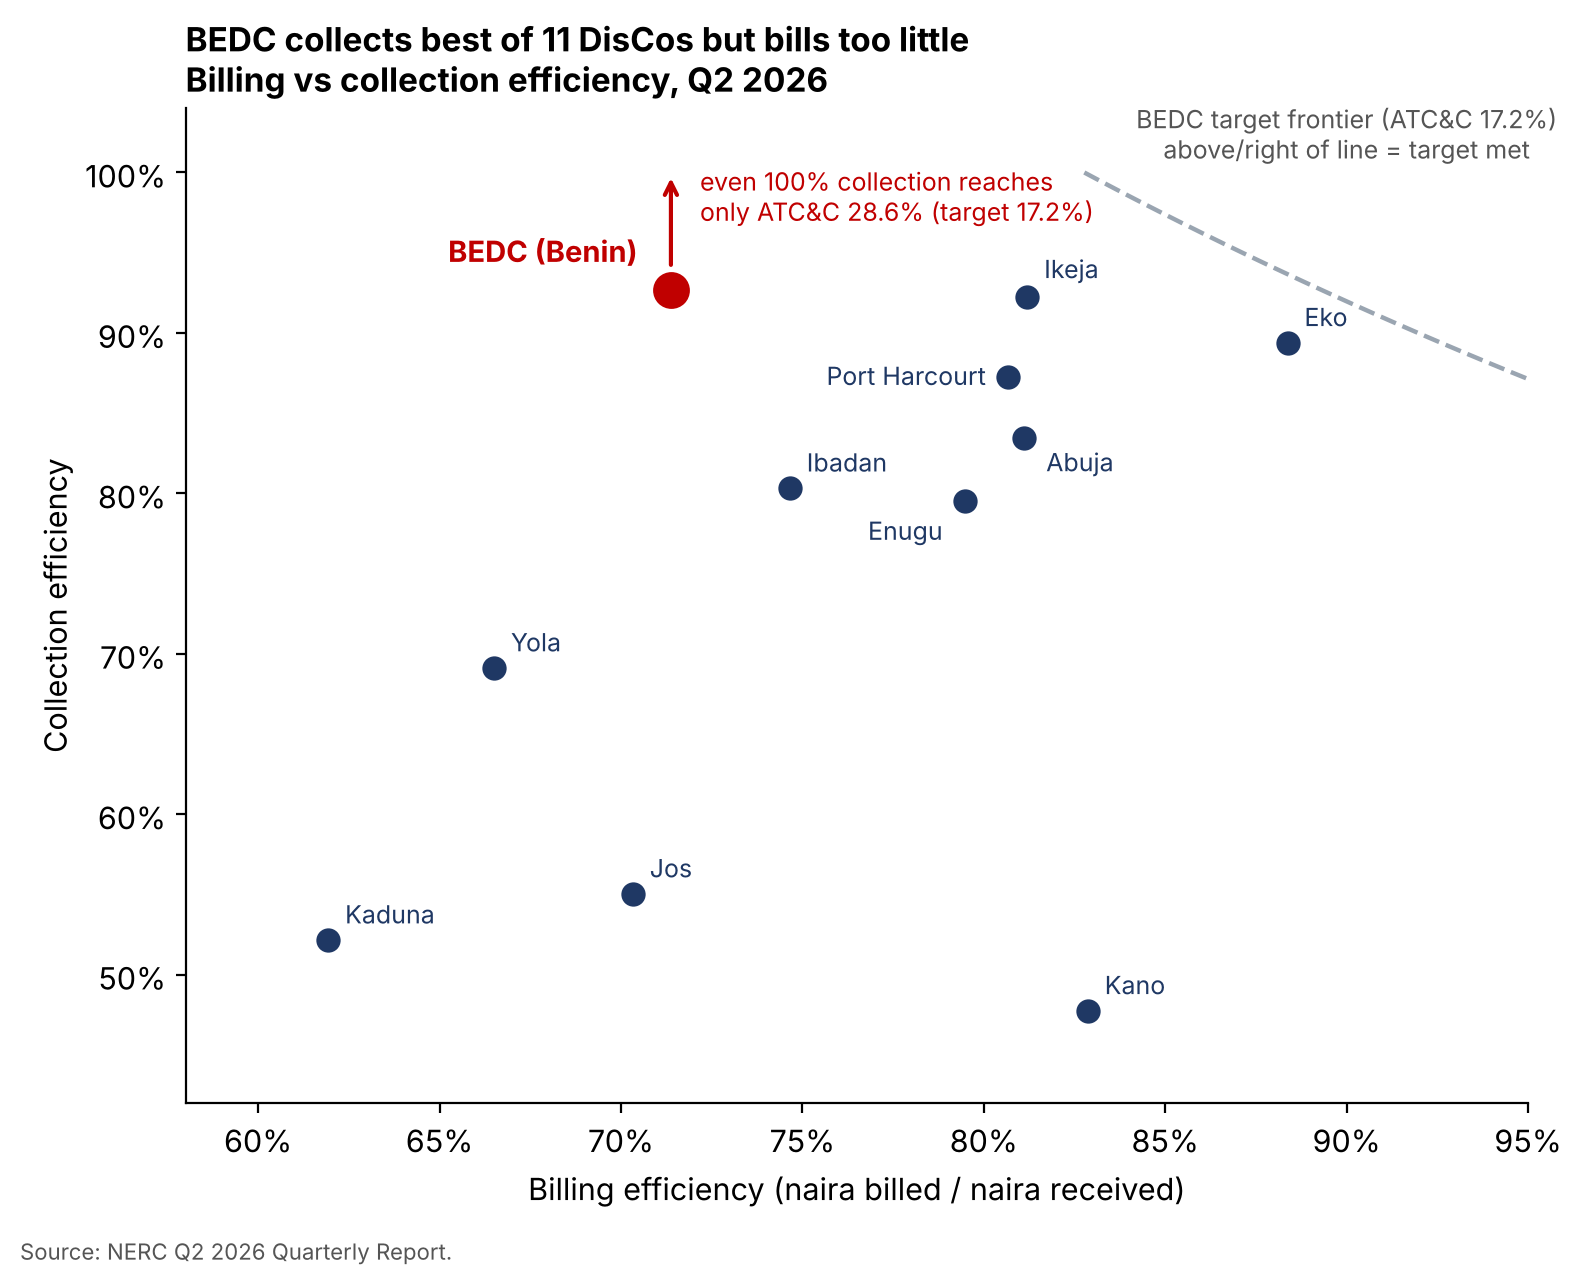

In [9]:
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
NAVY, RED, GREY, VIOLET, GREEN = "#1F3864", "#C00000", "#9AA5B1", "#6F55B8", "#2E8B57"
q2d = p.set_index("disco")

# Chart 1: billing vs collection efficiency, Q2 2026
fig, ax = plt.subplots(figsize=(8, 6.4))
be_line = np.linspace(1 - TARGET, 0.97, 100)
ax.plot(be_line, (1 - TARGET) / be_line, color=GREY, ls="--", lw=1.6)
ax.text(0.90, 1.005, "BEDC target frontier (ATC&C 17.2%)\nabove/right of line = target met", color="#555", fontsize=9, ha="center", va="bottom")
offsets = {"Benin": (-12, 10, "right"), "Ikeja": (6, 7, "left"), "Port Harcourt": (-8, -3, "right"), "Abuja": (8, -12, "left"),
           "Enugu": (-8, -14, "right")}
for name, r in q2d.iterrows():
    c = RED if name == ME else NAVY
    ax.scatter(r.be, r.ce, s=150 if name == ME else 60, color=c, zorder=3)
    dx, dy, ha = offsets.get(name, (6, 6, "left"))
    ax.annotate("BEDC (Benin)" if name == ME else name, (r.be, r.ce), xytext=(dx, dy), textcoords="offset points", ha=ha,
                fontsize=10.5 if name == ME else 9, color=c, fontweight="bold" if name == ME else None)
bm = q2d.loc[ME]
ax.annotate("", xy=(bm.be, 1.0), xytext=(bm.be, bm.ce + 0.012), arrowprops=dict(arrowstyle="->", color=RED, lw=1.5))
ax.text(bm.be + 0.008, 0.985, f"even 100% collection reaches\nonly ATC&C {atcc_if_perfect:.1%} (target 17.2%)", color=RED, fontsize=9, va="center")
ax.set(xlim=(0.58, 0.95), ylim=(0.42, 1.04), xlabel="Billing efficiency (naira billed / naira received)", ylabel="Collection efficiency")
ax.xaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1, 0)); ax.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1, 0))
ax.set_title("BEDC collects best of 11 DisCos but bills too little\nBilling vs collection efficiency, Q2 2026", loc="left", fontweight="bold", fontsize=12)
fig.text(0.01, 0.005, "Source: NERC Q2 2026 Quarterly Report.", fontsize=8, color="#555")
fig.tight_layout(rect=(0, 0.02, 1, 1)); fig.savefig("charts/1_billing_vs_collection_q2.png", dpi=150); plt.show()

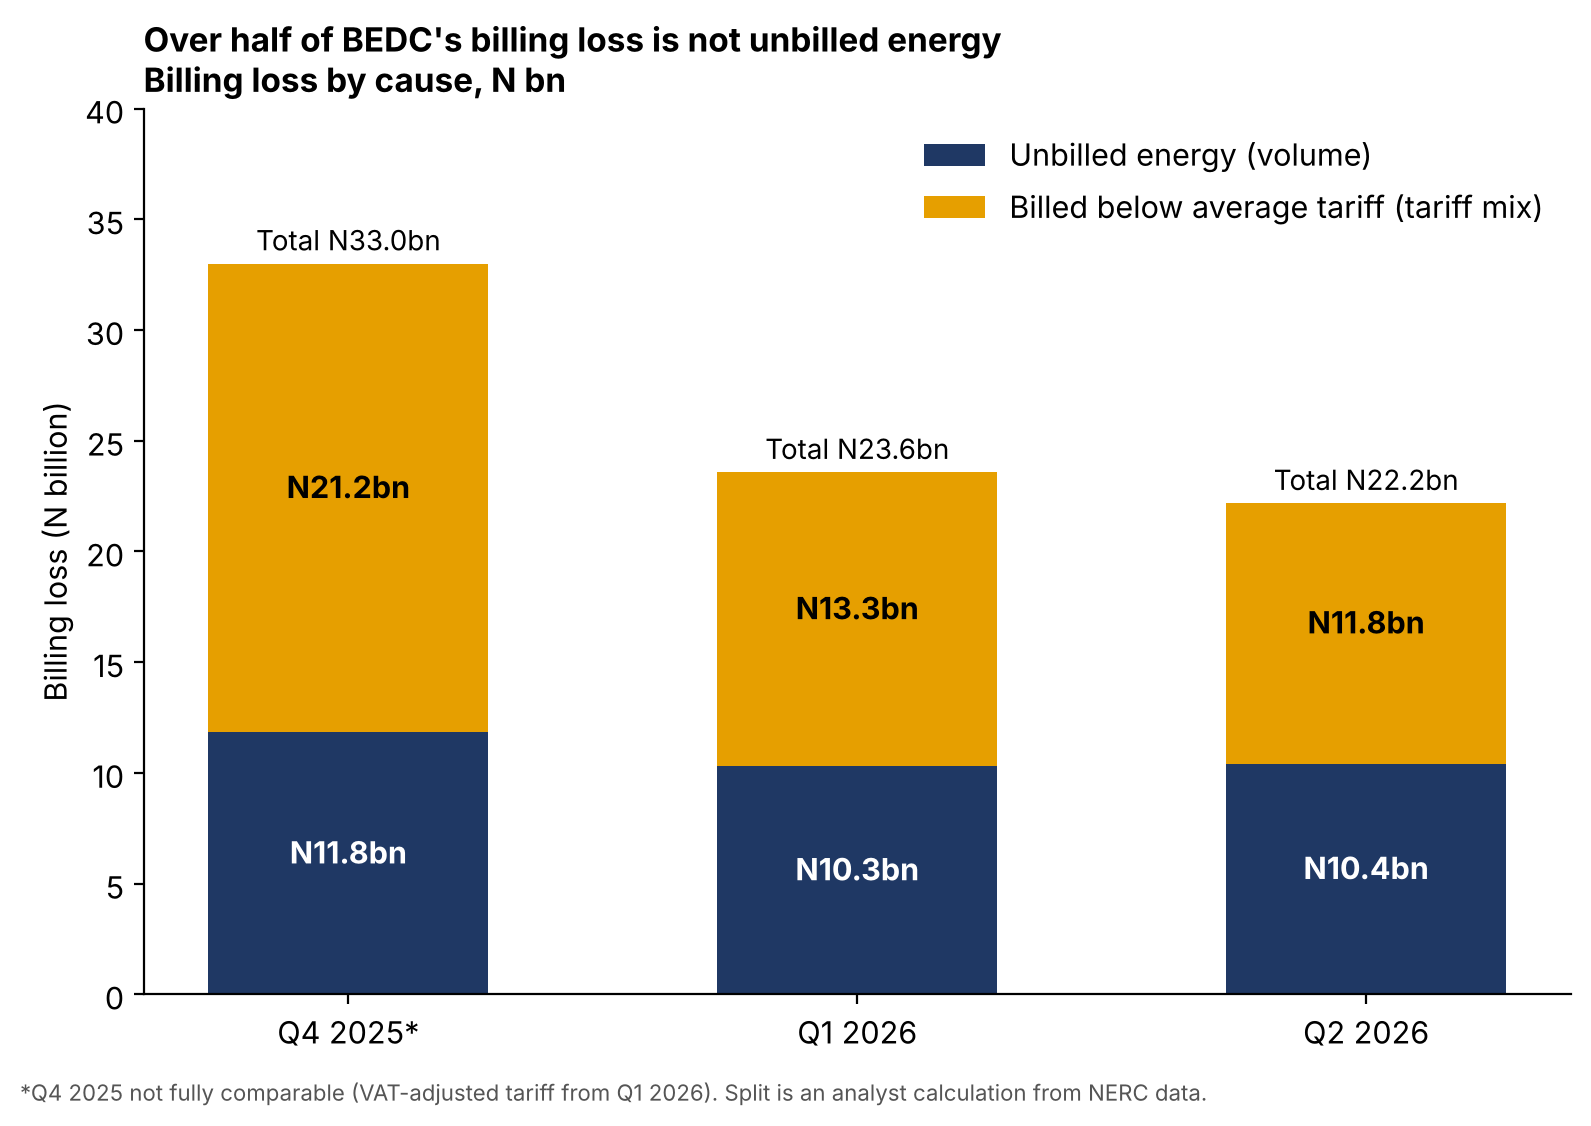

In [10]:
# Chart 2: billing loss split (unbilled energy vs billed-below-average-tariff)
fig, ax = plt.subplots(figsize=(8, 5.6)); x = np.arange(3)
ax.bar(x, b.volumetric_bn, color=NAVY, width=.55, label="Unbilled energy (volume)")
ax.bar(x, b.tariff_mix_bn, bottom=b.volumetric_bn, color="#E69F00", width=.55, label="Billed below average tariff (tariff mix)")
for i, (v, m) in enumerate(zip(b.volumetric_bn, b.tariff_mix_bn)):
    ax.text(i, v / 2, f"N{v:.1f}bn", ha="center", color="white", fontweight="bold")
    ax.text(i, v + m / 2, f"N{m:.1f}bn", ha="center", fontweight="bold")
    ax.text(i, v + m + 0.6, f"Total N{v + m:.1f}bn", ha="center", fontsize=10)
ax.set_xticks(x); ax.set_xticklabels(["Q4 2025*", "Q1 2026", "Q2 2026"]); ax.set(ylabel="Billing loss (N billion)", ylim=(0, 40))
ax.legend(frameon=False, loc="upper right")
ax.set_title("Over half of BEDC's billing loss is not unbilled energy\nBilling loss by cause, N bn", loc="left", fontweight="bold", fontsize=12)
fig.text(0.01, 0.005, "*Q4 2025 not fully comparable (VAT-adjusted tariff from Q1 2026). Split is an analyst calculation from NERC data.", fontsize=8, color="#555")
fig.tight_layout(rect=(0, 0.02, 1, 1)); fig.savefig("charts/2_billing_loss_split.png", dpi=150); plt.show()

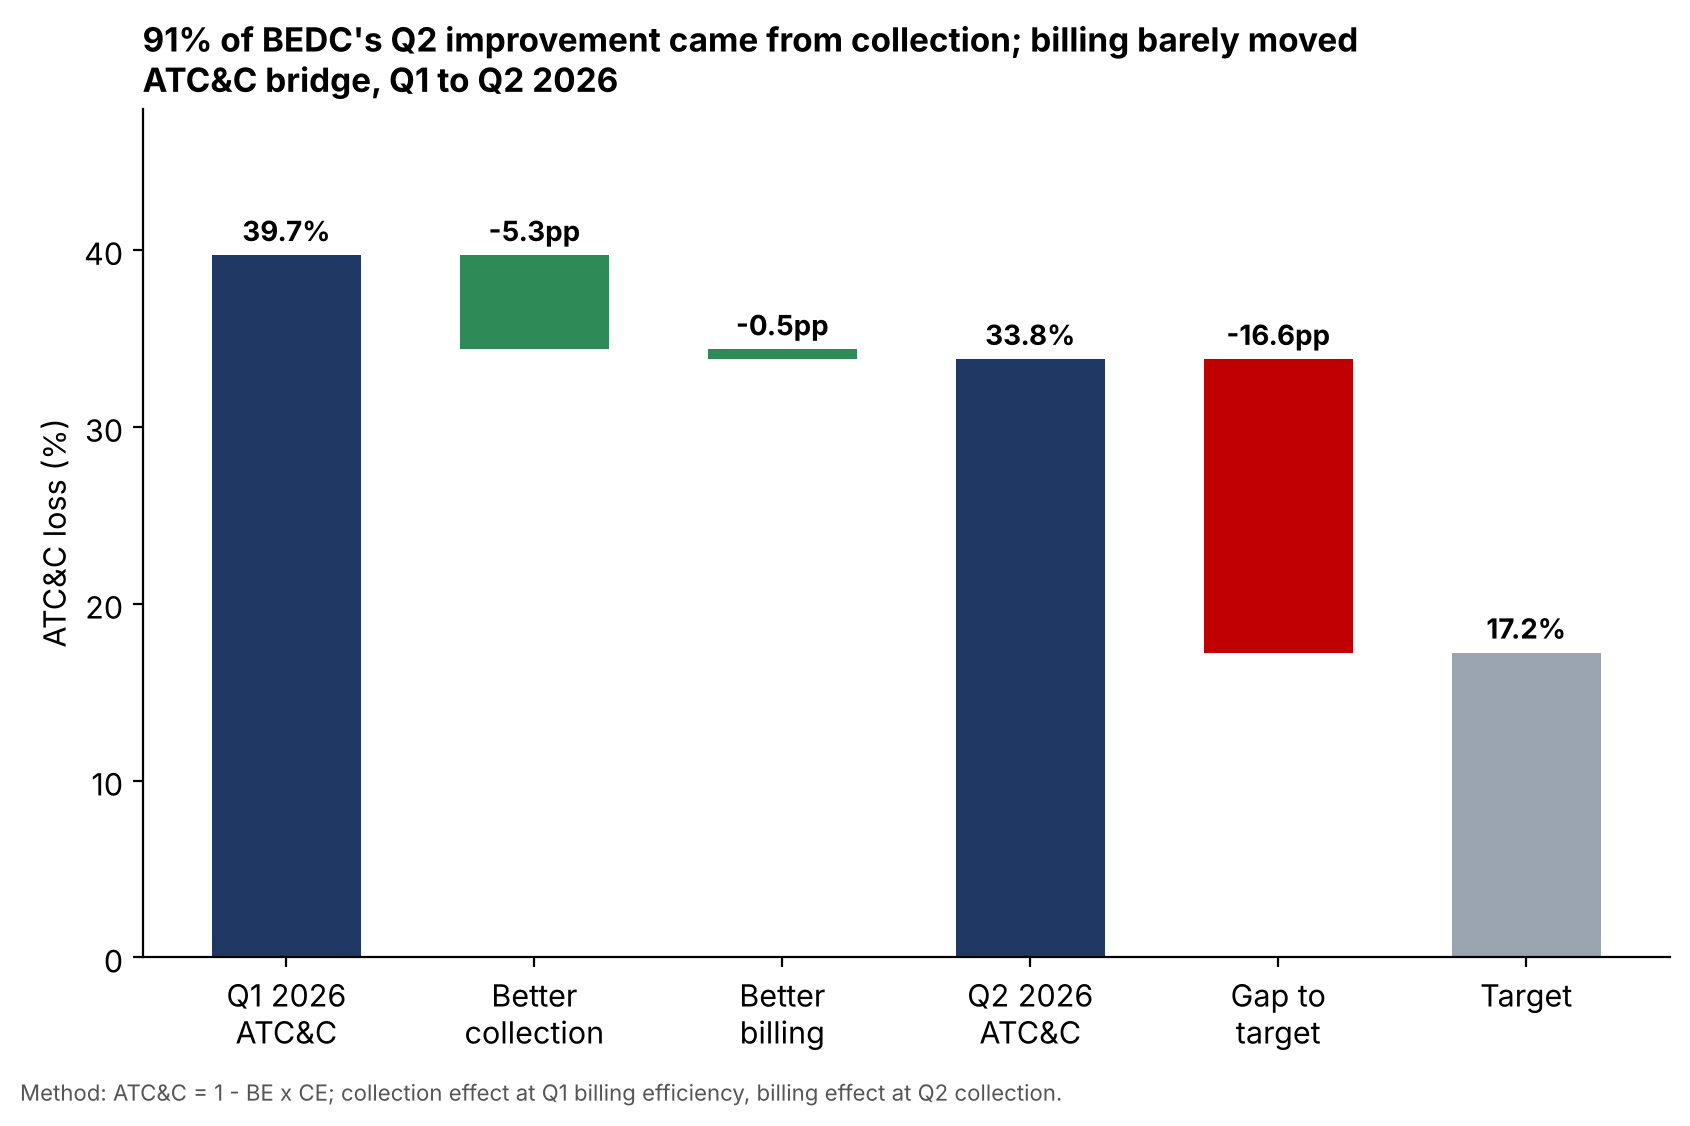

In [11]:
# Chart 3: ATC&C bridge Q1 -> Q2 2026
a1, a2 = q1.atcc * 100, q2.atcc * 100; tgt = TARGET * 100
steps = [("Q1 2026\nATC&C", a1, 0, NAVY), ("Better\ncollection", -coll_eff, a1, GREEN), ("Better\nbilling", -bill_eff, a1 - coll_eff, GREEN),
         ("Q2 2026\nATC&C", a2, 0, NAVY), ("Gap to\ntarget", -(a2 - tgt), a2, RED), ("Target", tgt, 0, GREY)]
fig, ax = plt.subplots(figsize=(8.5, 5.6))
for i, (lab, v, base_, c) in enumerate(steps):
    if v >= 0: ax.bar(i, v, bottom=base_, color=c, width=.6); y = base_ + v
    else:      ax.bar(i, -v, bottom=base_ + v, color=c, width=.6); y = base_
    txt = f"{v:.1f}%" if lab.endswith("ATC&C") or lab == "Target" else f"{v:+.1f}pp"
    ax.text(i, y + 0.8, txt, ha="center", fontweight="bold", fontsize=10)
ax.set_xticks(range(6)); ax.set_xticklabels([s[0] for s in steps]); ax.set(ylim=(0, 48), ylabel="ATC&C loss (%)")
ax.set_title(f"{coll_eff/total:.0%} of BEDC's Q2 improvement came from collection; billing barely moved\nATC&C bridge, Q1 to Q2 2026", loc="left", fontweight="bold", fontsize=12)
fig.text(0.01, 0.005, "Method: ATC&C = 1 - BE x CE; collection effect at Q1 billing efficiency, billing effect at Q2 collection.", fontsize=8, color="#555")
fig.tight_layout(rect=(0, 0.02, 1, 1)); fig.savefig("charts/3_atcc_bridge_q1_q2.png", dpi=150); plt.show()

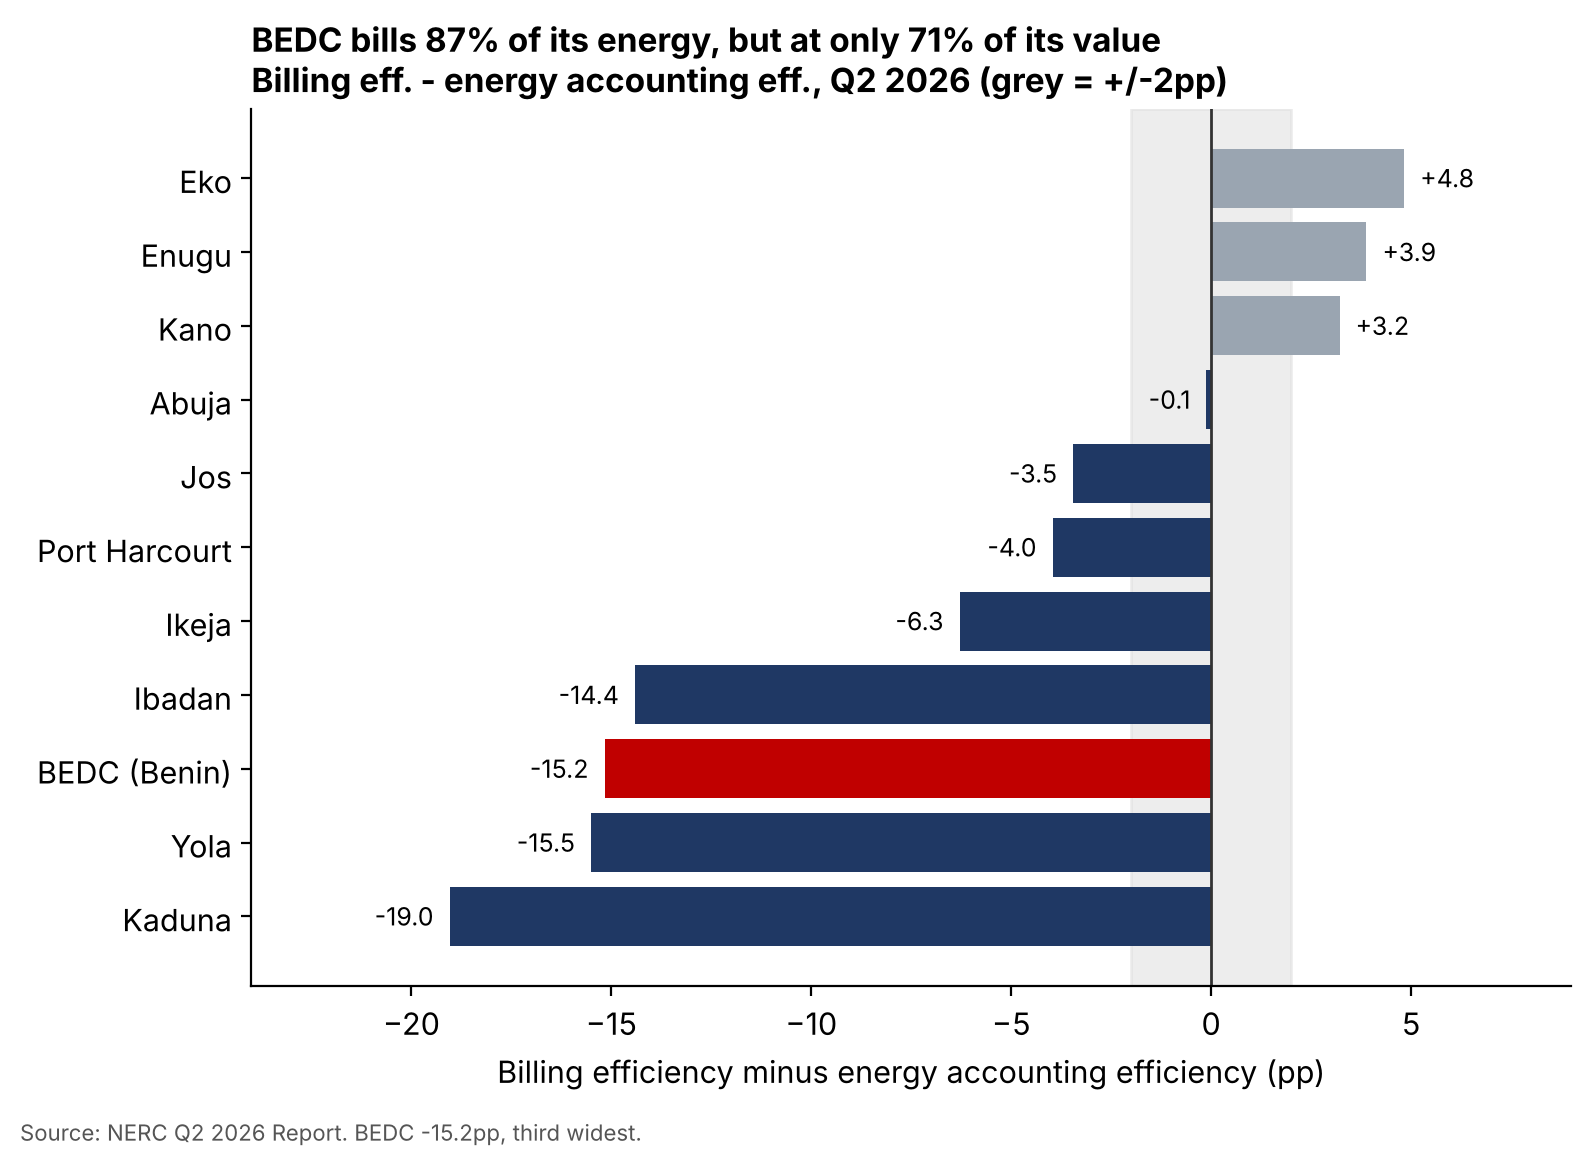

In [12]:
# Chart 4: BE minus EAE gap by DisCo, Q2 2026
v = p.set_index("disco").be_minus_eae_pp.sort_values()
fig, ax = plt.subplots(figsize=(8, 5.8))
cols_ = [RED if n == ME else (NAVY if x < 0 else GREY) for n, x in v.items()]
ax.barh([("BEDC (Benin)" if n == ME else n) for n in v.index], v.values, color=cols_)
for i, x in enumerate(v.values):
    ax.text(x + (0.4 if x >= 0 else -0.4), i, f"{x:+.1f}", va="center", ha="left" if x >= 0 else "right", fontsize=9)
ax.axvline(0, color="#333", lw=1); ax.axvspan(-2, 2, color="#DDD", alpha=.5, zorder=0); ax.set_xlim(-24, 9)
ax.set_xlabel("Billing efficiency minus energy accounting efficiency (pp)")
ax.set_title("BEDC bills 87% of its energy, but at only 71% of its value\nBilling eff. - energy accounting eff., Q2 2026 (grey = +/-2pp)", loc="left", fontweight="bold", fontsize=12)
fig.text(0.01, 0.005, "Source: NERC Q2 2026 Report. BEDC -15.2pp, third widest.", fontsize=8, color="#555")
fig.tight_layout(rect=(0, 0.02, 1, 1)); fig.savefig("charts/4_be_minus_eae_gap.png", dpi=150); plt.show()

**What the charts tell us:** BEDC sits high on collection but left on billing (chart 1), over half of its billing loss is tariff mix (chart 2), the Q2 gain came from collection (chart 3), and its BE-EAE gap is among the widest (chart 4).

**What they do not tell us:** the cause of the tariff-mix loss. That needs feeder, tariff-band, and customer-class data from BEDC.

## 9. Export the BEDC results table and limitations

In [13]:
view.round(4).to_csv("bedc_kpis.csv")
print("Saved bedc_kpis.csv")

Saved bedc_kpis.csv


### Limitations
- Public data is quarterly and company-level. Feeder, tariff-band, and customer-class data is internal to BEDC.
- Three quarters show direction, not a statistical trend. Q4 2025 is not fully comparable (NERC method change).
- Tariff realization and the volumetric / tariff-mix split are this analysis's own definitions, not NERC's.
- Scenario figures assume extra bills are collected at today's rate and are illustrations, not forecasts.

### Before you publish
Re-check a few typed figures against the NERC PDFs, and be ready to explain every formula and the tariff-mix definition in an interview.